# Avaliação — APIs de energia renovável e aprendizado de máquina

Consulte duas APIs públicas, organize os dados e resolva **duas tarefas**: classificar a fonte de empreendimentos da ANEEL e estimar a radiação solar em Petrolina (PE). Em **cada tarefa**, treine e compare **três algoritmos diferentes**. Este notebook fornece a consulta às APIs e os arquivos de dados; **você implementará a análise e os modelos**.

**Entrega:** um único link para um repositório público no GitHub com notebook executável, arquivos de dados, README e resultados. As instruções completas estão ao final e no enunciado separado.

## O que é recebido da API?

Uma requisição HTTP `GET` pede dados a uma URL. Os parâmetros identificam o recurso, o período e as variáveis. A resposta é **JSON**: um objeto com chaves e valores. Nas duas consultas desta avaliação, o acesso público **não exige login, token ou chave de API**. Se outra API exigir credenciais, não as publique no repositório.

Este código usa somente `json`, `urllib` e `csv`, bibliotecas que vêm com Python. `csv` serve apenas para exportar os dados recebidos; os imports para análise, tabelas, gráficos e ML são parte da sua implementação.

In [1]:
import json
import urllib.parse
import urllib.request
import csv

A função a seguir monta a URL, abre a conexão, verifica o status HTTP e converte o JSON. Se houver falha na rede ou na API, exibe uma mensagem de erro.

In [2]:
def consultar_api(endereco, parametros):
    url = endereco + "?" + urllib.parse.urlencode(parametros)
    try:
        with urllib.request.urlopen(url, timeout=30) as resposta:
            return json.load(resposta)
    except Exception as erro:
        raise RuntimeError(f"Não foi possível consultar a API: {erro}") from erro

# Tarefa 1 — Classificação (ANEEL)

**Pergunta:** a partir da potência e da localização de um empreendimento, é possível classificar sua fonte como **Solar, Eólica ou Hidráulica**?

A fonte é uma **categoria**: o problema é de classificação. O conjunto [SIGA da ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel) registra empreendimentos em várias fases. Usamos `UFV` (solar fotovoltaica), `EOL` (eólica) e três categorias hidráulicas: `UHE`, `PCH`, `CGH`. Estas três últimas formarão uma única classe, *Hidráulica*. A tarefa trata da **categoria do cadastro**, não da quantidade de energia gerada.

### Atributos originais da resposta

| Campo da API | Significado | Uso na tarefa |
|---|---|---|
| `SigTipoGeracao` | Sigla do tipo de geração (`UFV`, `EOL`, `UHE`, `PCH`, `CGH`) | Origina o alvo `fonte`; **não entra em X** |
| `MdaPotenciaOutorgadaKw` | Potência outorgada do empreendimento, em quilowatts (kW) | Entrada `potencia_kw`; potência nominal autorizada, não energia produzida |
| `NumCoordNEmpreendimento` | Latitude aproximada do empreendimento, em graus decimais | Entrada `latitude` |
| `NumCoordEEmpreendimento` | Longitude aproximada do empreendimento, em graus decimais | Entrada `longitude` |
| `CodCEG`, `NomEmpreendimento` e campos de combustível | Código, nome e descrição associados ao empreendimento e à fonte | **Não usar como entradas**: podem revelar a classe |

A resposta CKAN contém `success` e `result`; dentro de `result`, `records` são as linhas, `fields` descrevem as colunas e `total` indica o total encontrado para o filtro. O CSV final terá **três atributos numéricos e a classe**. Quantidades consultadas têm limite por tipo e não representam a participação de cada fonte na matriz brasileira.

### 1. Consultar a ANEEL

O recurso SIGA é acessado pela API pública CKAN/DataStore. `resource_id` aponta para o conjunto; `filters` seleciona uma sigla; `limit` limita o retorno de cada pedido. Não há etapa de autenticação para esta consulta pública.

In [3]:
URL_ANEEL = "https://dadosabertos.aneel.gov.br/api/3/action/datastore_search"
ID_RECURSO = "11ec447d-698d-4ab8-977f-b424d5deee6a"
SIGLAS = ["UFV", "EOL", "UHE", "PCH", "CGH"]
print("API ANEEL: consulta pública, sem token")

API ANEEL: consulta pública, sem token


In [4]:
registros_aneel = []
for sigla in SIGLAS:
    parametros = {
        "resource_id": ID_RECURSO,
        "filters": json.dumps({"SigTipoGeracao": sigla}),
        "limit": 1200,
    }
    resposta = consultar_api(URL_ANEEL, parametros)
    if not resposta.get("success"):
        raise ValueError(f"Consulta da ANEEL falhou para {sigla}")
    linhas = resposta["result"]["records"]
    print(f"{sigla}: {len(linhas)} linhas recebidas")
    registros_aneel.extend(linhas)
print("Total de linhas recebidas:", len(registros_aneel))

UFV: 1200 linhas recebidas
EOL: 1200 linhas recebidas
UHE: 221 linhas recebidas
PCH: 537 linhas recebidas
CGH: 718 linhas recebidas
Total de linhas recebidas: 3876


### 2. Gerar o CSV para a tarefa

A API pode fornecer números como texto, inclusive com vírgula decimal. O tratamento abaixo converte esses valores, descarta linhas sem potência ou coordenadas e transforma as siglas em três classes. Cada linha do arquivo final representa **um empreendimento**. Confira a quantidade de exemplos por classe durante sua análise; se necessário, discuta o desequilíbrio entre classes.

In [5]:
def numero(valor):
    texto = str(valor).strip()
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    try:
        return float(texto)
    except ValueError:
        return None

fontes = {"UFV": "Solar", "EOL": "Eólica", "UHE": "Hidráulica",
          "PCH": "Hidráulica", "CGH": "Hidráulica"}
linhas_classificacao = []
for registro in registros_aneel:
    potencia = numero(registro.get("MdaPotenciaOutorgadaKw"))
    latitude = numero(registro.get("NumCoordNEmpreendimento"))
    longitude = numero(registro.get("NumCoordEEmpreendimento"))
    fonte = fontes.get(registro.get("SigTipoGeracao"))
    if fonte and all(valor is not None for valor in (potencia, latitude, longitude)):
        linhas_classificacao.append([potencia, latitude, longitude, fonte])
if len(linhas_classificacao) < 90:
    raise ValueError("Poucos registros válidos: confira a resposta da ANEEL")
print("Linhas válidas:", len(linhas_classificacao))
print("Primeiro exemplo:", linhas_classificacao[0])

Linhas válidas: 3876
Primeiro exemplo: [20.48, -10.44277778, -64.15194444, 'Solar']


In [ ]:
with open("dataset/aneel_classificacao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["potencia_kw", "latitude", "longitude", "fonte"])
    escritor.writerows(linhas_classificacao)
print("Salvo: aneel_classificacao_orange.csv")

Salvo: aneel_classificacao_orange.csv


### O que você deve fazer — classificação

1. Carregue o CSV, confira os tipos das colunas, as contagens por classe, valores ausentes e distribuições relevantes. Explique `X` (três entradas) e `y` (`fonte`).
2. Faça uma divisão **estratificada** de treino/teste, por exemplo 80%/20%, com semente fixa. Ajustes de escala aprendidos dos dados devem ser feitos **somente com o treino**.
3. Escolha, justifique e treine **três classificadores diferentes** usando a mesma divisão. Eles **não estão importados nem implementados** neste notebook.
4. Compare Accuracy, Precision, Recall e F1. Declare o tipo de média usado nas métricas por classe (por exemplo, `macro`) e apresente a matriz de confusão.
5. Explique qual modelo escolheria, quais classes ele mais confunde e por que potência/localização podem não bastar para uma aplicação real. Não use `SigTipoGeracao`, nomes, CEG ou descrições da fonte como entradas.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico(s) ou matriz de confusão e interpretação escrita.

## Análise e modelos — classificação

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("aneel_classificacao_orange.csv")

print(df.head())
print("\nTipos das colunas:")
print(df.dtypes)
print("\nValores ausentes:")
print(df.isnull().sum())
print("\nQuantidade por classe:")
print(df["fonte"].value_counts())

   potencia_kw   latitude  longitude  fonte
0        20.48 -10.442778 -64.151944  Solar
1      5000.00  -6.003889 -40.274722  Solar
2        12.26 -23.557778 -46.734000  Solar
3         3.00 -23.558889 -46.735000  Solar
4         1.70 -23.493819 -46.845000  Solar

Tipos das colunas:
potencia_kw    float64
latitude       float64
longitude      float64
fonte           object
dtype: object

Valores ausentes:
potencia_kw    0
latitude       0
longitude      0
fonte          0
dtype: int64

Quantidade por classe:
fonte
Hidráulica    1476
Solar         1200
Eólica        1200
Name: count, dtype: int64



Resumo dos dados:
        potencia_kw     latitude    longitude
count  3.876000e+03  3876.000000  3876.000000
mean   4.201468e+04   -12.693951   -46.158299
std    3.016366e+05     9.500523     8.357453
min    1.600000e-01   -33.722806   -69.941389
25%    4.400000e+02   -21.142110   -52.561817
50%    1.268000e+04   -10.469532   -47.393697
75%    3.000000e+04    -4.127788   -41.280013
max    1.123310e+07     3.831392     0.000000


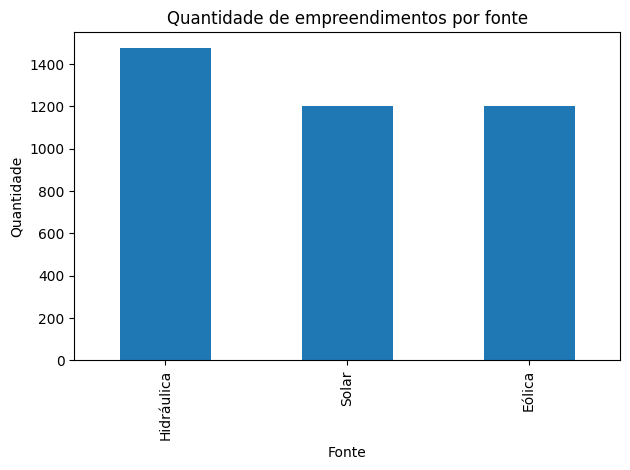

X: ['potencia_kw', 'latitude', 'longitude']
y: fonte
Treino: 3100
Teste: 776


In [8]:
print("\nResumo dos dados:")
print(df.describe())

fig, ax = plt.subplots()
df["fonte"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Quantidade de empreendimentos por fonte")
ax.set_xlabel("Fonte")
ax.set_ylabel("Quantidade")
plt.tight_layout()
plt.show()

X = df[["potencia_kw", "latitude", "longitude"]]
y = df["fonte"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X:", list(X.columns))
print("y: fonte")
print("Treino:", len(X_treino))
print("Teste:", len(X_teste))

In [9]:
modelos_classificacao = {
    "Regressão Logística": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000))
    ]),
    "KNN": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

resultados_classificacao = []
predicoes_classificacao = {}

for nome, modelo in modelos_classificacao.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)
    predicoes_classificacao[nome] = previsoes

    resultados_classificacao.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_teste, previsoes),
        "Precision (macro)": precision_score(y_teste, previsoes, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_teste, previsoes, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_teste, previsoes, average="macro", zero_division=0)
    })

resultado_clf = pd.DataFrame(resultados_classificacao)
resultado_clf = resultado_clf.sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
print(resultado_clf.round(4).to_string(index=False))

             Modelo  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)
      Random Forest    0.9755             0.9769          0.9741      0.9753
                KNN    0.9652             0.9663          0.9636      0.9648
Regressão Logística    0.8247             0.8282          0.8214      0.8197


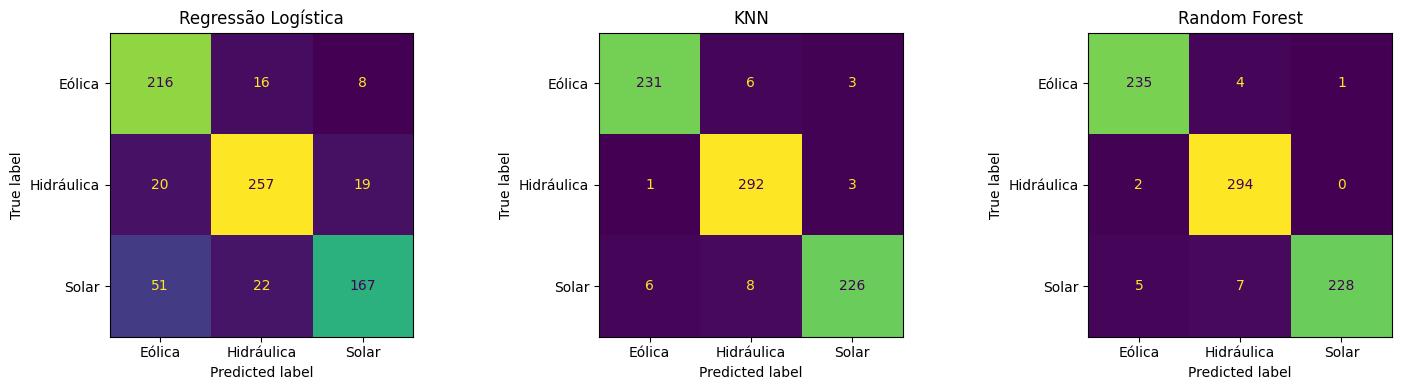

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
classes = sorted(y.unique())

for ax, (nome, previsoes) in zip(axes, predicoes_classificacao.items()):
    cm = confusion_matrix(y_teste, previsoes, labels=classes)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(nome)

plt.tight_layout()
plt.show()

### Interpretação da classificação

A `Accuracy` mostra a proporção total de acertos. Precision, Recall e F1 foram calculados com média `macro`, então cada uma das três classes tem o mesmo peso na média. A matriz de confusão mostra quais fontes foram confundidas.

Para a escolha do modelo, considero principalmente o `F1 (macro)`, junto com as outras métricas e a matriz de confusão. O resultado abaixo é preenchido pelo próprio notebook depois da execução.

In [11]:
melhor_clf = resultado_clf.iloc[0]
print("Modelo com maior F1 (macro):", melhor_clf["Modelo"])
print("F1 (macro):", round(melhor_clf["F1 (macro)"], 4))
print("Accuracy:", round(melhor_clf["Accuracy"], 4))

print("\nAs variáveis usadas foram somente potência, latitude e longitude.")
print("Em uma aplicação real, essas variáveis podem não ser suficientes porque empreendimentos de fontes diferentes podem existir em regiões parecidas e ter faixas de potência semelhantes.")
print("Por isso, outras informações técnicas e geográficas poderiam melhorar a classificação, mas não foram usadas aqui porque o exercício restringe as entradas.")

Modelo com maior F1 (macro): Random Forest
F1 (macro): 0.9753
Accuracy: 0.9755

As variáveis usadas foram somente potência, latitude e longitude.
Em uma aplicação real, essas variáveis podem não ser suficientes porque empreendimentos de fontes diferentes podem existir em regiões parecidas e ter faixas de potência semelhantes.
Por isso, outras informações técnicas e geográficas poderiam melhorar a classificação, mas não foram usadas aqui porque o exercício restringe as entradas.


# Tarefa 2 — Regressão (Open-Meteo)

**Pergunta:** dadas as condições meteorológicas e a hora local em Petrolina (PE), qual é a radiação solar horizontal média naquela hora? A resposta é um **número**, então o problema é de regressão.

A API histórica do [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) devolve dados horários para coordenadas e período escolhidos. Usamos **1º de abril a 30 de junho de 2025**, em horário local. São dados históricos estimados por modelos/reanálise, não leituras de um sensor particular. **Radiação em W/m² não equivale à energia em kWh nem à geração de um painel.**

### Parâmetros da requisição

| Parâmetro | Valor nesta avaliação | Significado |
|---|---|---|
| `latitude`, `longitude` | `-9.39`, `-40.50` | Coordenadas aproximadas de Petrolina (PE) |
| `start_date`, `end_date` | `2025-04-01`, `2025-06-30` | Período histórico consultado, inclusive as datas extremas |
| `timezone` | `America/Recife` | Faz `time` representar a hora local |
| `hourly` | Lista das cinco variáveis abaixo | Solicita valores horários em JSON |

### Atributos do conjunto de dados

| Campo da API → CSV | Significado e unidade | Uso na tarefa |
|---|---|---|
| `time` → `data_hora` | Data e hora local de cada registro | Ordenar e separar por tempo; não é entrada em X |
| `temperature_2m` → `temperatura_c` | Temperatura do ar a 2 m, em °C | Entrada |
| `relative_humidity_2m` → `umidade_pct` | Umidade relativa a 2 m, em % | Entrada |
| `cloud_cover` → `nuvens_pct` | Cobertura total de nuvens, em % | Entrada |
| `wind_speed_10m` → `vento_kmh` | Velocidade do vento a 10 m, em km/h | Entrada |
| `time` → `hora` | Hora local extraída da data, de 7 a 17 nesta amostra | Entrada |
| `shortwave_radiation` → `radiacao_w_m2` | Radiação solar global horizontal média da hora anterior, em W/m² | Alvo numérico `y`; **não entra em X** |

A resposta inclui `hourly` (listas dos valores, alinhadas por índice), `hourly_units` (unidades) e metadados da localização. Cada linha do CSV final representa **uma hora entre 7h e 17h**; esse recorte reduz o domínio de horas noturnas, mas não remove a importância da hora para a previsão.

### 3. Consultar o histórico meteorológico

A chamada usa GET, sem cadastro ou chave para esta consulta pública de uso educacional. Se `hourly` faltar, verifique datas e parâmetros.

In [12]:
URL_METEO = "https://archive-api.open-meteo.com/v1/archive"
parametros_meteo = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "timezone": "America/Recife",
    "hourly": ",".join(["temperature_2m", "relative_humidity_2m",
                         "cloud_cover", "wind_speed_10m", "shortwave_radiation"]),
}
print("Open-Meteo: consulta pública, sem token")

Open-Meteo: consulta pública, sem token


In [13]:
resposta_meteo = consultar_api(URL_METEO, parametros_meteo)
if "hourly" not in resposta_meteo:
    raise ValueError("Resposta sem a seção hourly")
horas_api = resposta_meteo["hourly"]
print("Campos recebidos:", list(horas_api))
print("Unidades informadas pela API:", resposta_meteo.get("hourly_units", {}))
print("Quantidade de horários:", len(horas_api["time"]))

Campos recebidos: ['time', 'temperature_2m', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m', 'shortwave_radiation']
Unidades informadas pela API: {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'cloud_cover': '%', 'wind_speed_10m': 'km/h', 'shortwave_radiation': 'W/m²'}
Quantidade de horários: 2184


### 4. Gerar o CSV horário

As listas de `hourly` são alinhadas: o índice 0 de cada variável se refere ao índice 0 de `time`. Percorremos esses índices, mantemos as horas de 7h a 17h e descartamos linhas com valores ausentes. A data permanece ordenada para facilitar uma avaliação temporal.

In [14]:
nomes_api = ["temperature_2m", "relative_humidity_2m", "cloud_cover",
             "wind_speed_10m", "shortwave_radiation"]
linhas_regressao = []
for indice, data_hora in enumerate(horas_api["time"]):
    hora = int(data_hora[11:13])
    valores = [horas_api[nome][indice] for nome in nomes_api]
    if 7 <= hora <= 17 and all(valor is not None for valor in valores):
        linhas_regressao.append([data_hora, *valores[:4], hora, valores[4]])
if len(linhas_regressao) < 100:
    raise ValueError("Poucos horários válidos: confira a resposta do Open-Meteo")
print("Horas válidas:", len(linhas_regressao))
print("Primeiro exemplo:", linhas_regressao[0])

Horas válidas: 1001
Primeiro exemplo: ['2025-04-01T07:00', 25.3, 74, 100, 17.7, 7, 116.0]


In [ ]:
with open("dataset/meteo_regressao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["data_hora", "temperatura_c", "umidade_pct",
                       "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"])
    escritor.writerows(linhas_regressao)
print("Salvo: meteo_regressao_orange.csv")

Salvo: meteo_regressao_orange.csv


### O que você deve fazer — regressão

1. Carregue o CSV, explique as colunas, examine valores ausentes e apresente ao menos uma visualização. Defina `X` (cinco entradas) e `y` (`radiacao_w_m2`).
2. Mantenha as linhas em ordem de `data_hora`: use aproximadamente **80% das primeiras horas para treino** e as 20% finais para teste. Evite embaralhar as horas. Ajuste transformações apenas com o treino.
3. Escolha, justifique e treine **três algoritmos de regressão diferentes** com a mesma divisão. Os imports e a implementação são sua responsabilidade.
4. Compare **MAE** (W/m²), **MSE** ((W/m²)²) e **R²**; faça um gráfico de valores reais × previstos de pelo menos um modelo.
5. Interprete os erros, discuta o peso da hora e explique por que essa estimativa da radiação **não prevê automaticamente a energia produzida** por um sistema fotovoltaico.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico e interpretação escrita. Nenhum valor de `radiacao_w_m2` deve ser usado para criar uma entrada do mesmo registro.

## Análise e modelos — regressão

Neste caso o objetivo é prever `radiacao_w_m2`. As cinco entradas são temperatura, umidade, cobertura de nuvens, vento e hora. Como os dados são temporais, as primeiras 80% das linhas ficam no treino e as últimas 20% no teste.

In [16]:
df_meteo = pd.read_csv("meteo_regressao_orange.csv")
df_meteo["data_hora"] = pd.to_datetime(df_meteo["data_hora"])
df_meteo = df_meteo.sort_values("data_hora").reset_index(drop=True)

print(df_meteo.head())
print("\nTipos das colunas:")
print(df_meteo.dtypes)
print("\nValores ausentes:")
print(df_meteo.isnull().sum())
print("\nResumo:")
print(df_meteo.describe())

            data_hora  temperatura_c  umidade_pct  nuvens_pct  vento_kmh  \
0 2025-04-01 07:00:00           25.3           74         100       17.7   
1 2025-04-01 08:00:00           26.5           66         100       18.1   
2 2025-04-01 09:00:00           28.4           55          97       18.0   
3 2025-04-01 10:00:00           30.8           44          21       18.4   
4 2025-04-01 11:00:00           32.7           36          26       20.1   

   hora  radiacao_w_m2  
0     7          116.0  
1     8          269.0  
2     9          529.0  
3    10          797.0  
4    11          880.0  

Tipos das colunas:
data_hora        datetime64[ns]
temperatura_c           float64
umidade_pct               int64
nuvens_pct                int64
vento_kmh               float64
hora                      int64
radiacao_w_m2           float64
dtype: object

Valores ausentes:
data_hora        0
temperatura_c    0
umidade_pct      0
nuvens_pct       0
vento_kmh        0
hora             0
ra

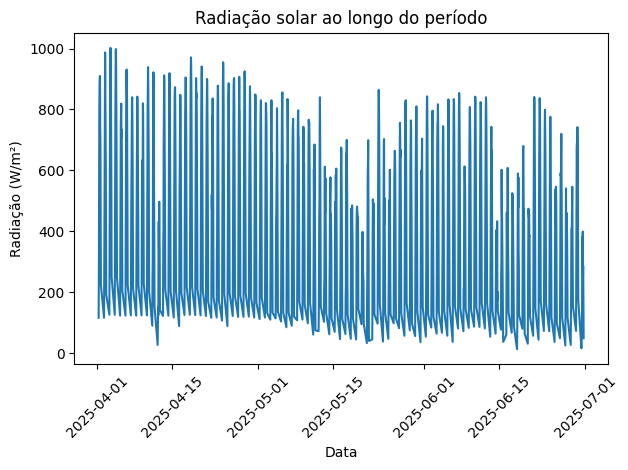

X: ['temperatura_c', 'umidade_pct', 'nuvens_pct', 'vento_kmh', 'hora']
y: radiacao_w_m2
Treino: 800
Teste: 201
Data final do treino: 2025-06-12 14:00:00
Data inicial do teste: 2025-06-12 15:00:00


In [17]:
fig, ax = plt.subplots()
ax.plot(df_meteo["data_hora"], df_meteo["radiacao_w_m2"])
ax.set_title("Radiação solar ao longo do período")
ax.set_xlabel("Data")
ax.set_ylabel("Radiação (W/m²)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

X = df_meteo[["temperatura_c", "umidade_pct", "nuvens_pct", "vento_kmh", "hora"]]
y = df_meteo["radiacao_w_m2"]

ponto_corte = int(len(df_meteo) * 0.80)
X_treino = X.iloc[:ponto_corte]
X_teste = X.iloc[ponto_corte:]
y_treino = y.iloc[:ponto_corte]
y_teste = y.iloc[ponto_corte:]

print("X:", list(X.columns))
print("y: radiacao_w_m2")
print("Treino:", len(X_treino))
print("Teste:", len(X_teste))
print("Data final do treino:", df_meteo.loc[ponto_corte - 1, "data_hora"])
print("Data inicial do teste:", df_meteo.loc[ponto_corte, "data_hora"])

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modelos_regressao = {
    "Regressão Linear": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", SVR())
    ])
}

resultados_regressao = []
predicoes_regressao = {}

for nome, modelo in modelos_regressao.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)
    predicoes_regressao[nome] = previsoes

    mse = mean_squared_error(y_teste, previsoes)
    resultados_regressao.append({
        "Modelo": nome,
        "MAE (W/m²)": mean_absolute_error(y_teste, previsoes),
        "MSE ((W/m²)²)": mse,
        "R²": r2_score(y_teste, previsoes)
    })

resultado_reg = pd.DataFrame(resultados_regressao)
resultado_reg = resultado_reg.sort_values("MAE (W/m²)").reset_index(drop=True)
print(resultado_reg.round(4).to_string(index=False))

          Modelo  MAE (W/m²)  MSE ((W/m²)²)      R²
   Random Forest     66.8042      7307.4179  0.8442
Regressão Linear    145.2049     30034.2011  0.3598
             SVR    181.0850     47441.6393 -0.0112


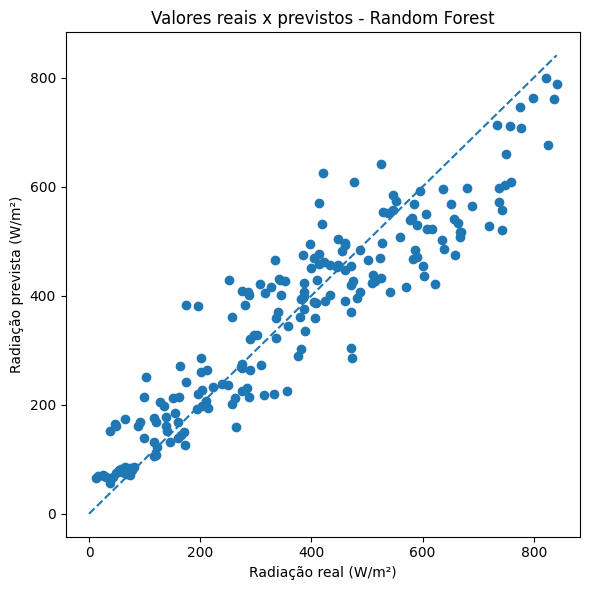

Modelo com menor MAE: Random Forest
MAE: 66.8042 W/m²
MSE: 7307.4179
R²: 0.8442


In [19]:
nome_modelo = resultado_reg.iloc[0]["Modelo"]
previsoes = predicoes_regressao[nome_modelo]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_teste, previsoes)
limite = max(y_teste.max(), previsoes.max())
ax.plot([0, limite], [0, limite], linestyle="--")
ax.set_title("Valores reais x previstos - " + nome_modelo)
ax.set_xlabel("Radiação real (W/m²)")
ax.set_ylabel("Radiação prevista (W/m²)")
plt.tight_layout()
plt.show()

melhor_reg = resultado_reg.iloc[0]
print("Modelo com menor MAE:", melhor_reg["Modelo"])
print("MAE:", round(melhor_reg["MAE (W/m²)"], 4), "W/m²")
print("MSE:", round(melhor_reg["MSE ((W/m²)²)"], 4))
print("R²:", round(melhor_reg["R²"], 4))

### Interpretação da regressão

O MAE indica, em média, quantos W/m² as previsões ficaram afastadas dos valores reais. O MSE dá mais peso aos erros maiores e o R² indica quanto da variação do alvo é explicada pelo modelo no conjunto de teste.

A `hora` é importante porque a radiação muda bastante durante o dia. Mesmo com as variáveis meteorológicas, a posição da hora ajuda o modelo a diferenciar períodos com níveis de radiação diferentes.

Também é importante lembrar que a radiação em W/m² é uma medida de potência solar incidente. Ela não informa sozinha a energia produzida por um sistema fotovoltaico, porque a produção depende também de fatores como área dos módulos, eficiência, orientação, inclinação, temperatura dos módulos e perdas do sistema.

# Entrega pelo GitHub

Envie **apenas o link do repositório público**. Organize-o com:

- `README.md` contendo objetivo, fontes e período dos dados, instruções para executar o notebook e resumo dos resultados;
- notebook `.ipynb` com a consulta às APIs, sua análise, os **três classificadores e os três regressores**, todos os imports necessários adicionados por você e conclusões em Markdown;
- os dois CSVs gerados (ou instruções completas e testadas para reproduzi-los) e eventuais figuras utilizadas.

Verifique se o notebook roda **na ordem das células** a partir de um ambiente limpo. Não inclua senhas, tokens ou arquivos sem relação com a avaliação. A banca deve conseguir encontrar as seis comparações e as respostas às duas tarefas sem procurar uma agulha no palheiro.

### Fontes

- [ANEEL — SIGA](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel)
- [ANEEL — recurso e campos usados](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel/resource/11ec447d-698d-4ab8-977f-b424d5deee6a)
- [Open-Meteo — histórico e unidades](https://open-meteo.com/en/docs/historical-weather-api)